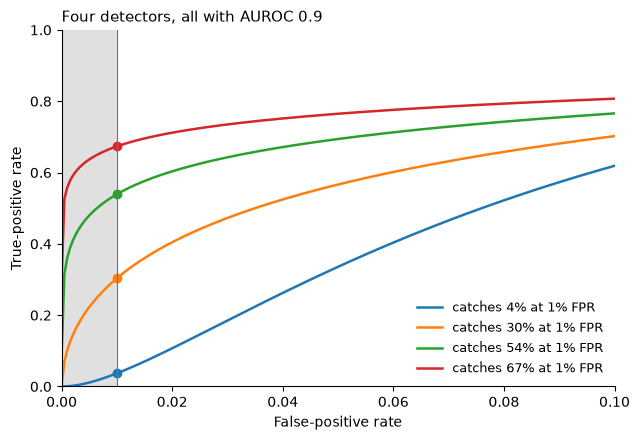

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

plt.style.use("default")

AUROC = 0.90
fpr = np.linspace(1e-6, 1, 2000)


def roc(shape):
    a = norm.ppf(AUROC) * np.sqrt(1 + shape ** 2)
    return norm.cdf(a + shape * norm.ppf(fpr))


plt.figure(figsize=(6.5, 4.5))

for shape in [2.0, 1.0, 0.6, 0.4]:
    tpr = roc(shape)
    at_1pct = np.interp(0.01, fpr, tpr)
    line, = plt.plot(fpr, tpr, lw=1.8, label=f"catches {at_1pct:.0%} at 1% FPR")
    plt.plot([0.01], [at_1pct], marker="o", ms=6, color=line.get_color())

plt.axvspan(0, 0.01, color="0.88", zorder=0)
plt.axvline(0.01, color="0.45", lw=0.8)
plt.xlim(0, 0.1)
plt.ylim(0, 1)
plt.xlabel("False-positive rate")
plt.ylabel("True-positive rate")
plt.title(f"Four detectors, all with AUROC {AUROC}", fontsize=11, loc="left")
plt.legend(frameon=False, fontsize=9, loc="lower right")
plt.gca().spines[["top", "right"]].set_visible(False)
plt.tight_layout()